#Install Libraries & Mount Google Drive

In [ ]:
!pip install mne pyedflib

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mne
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Dense, Dropout, Bidirectional, GlobalAveragePooling1D
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score

# Print TensorFlow version and confirm GPU availability

In [ ]:
print("TensorFlow version:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print(f"GPU is available: {gpus[0].name}" if gpus else "No GPU found.")

TensorFlow version: 2.18.0
GPU is available: /physical_device:GPU:0


# Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 1. Single Subject Walkthrough


===== PART 1: SINGLE SUBJECT =====
Extracting EDF parameters from /content/drive/MyDrive/archive/sleep-cassette/SC4001E0-PSG.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...


<ipython-input-4-8ea4d495936f>:6: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_file, preload=True)
<ipython-input-4-8ea4d495936f>:6: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_file, preload=True)
<ipython-input-4-8ea4d495936f>:6: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(psg_file, preload=True)


Reading 0 ... 7949999  =      0.000 ... 79499.990 secs...


<ipython-input-4-8ea4d495936f>:8: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


Channels: ['EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal', 'Resp oro-nasal', 'EMG submental', 'Temp rectal', 'Event marker']
Sampling frequency: 100.0
Using matplotlib as 2D backend.


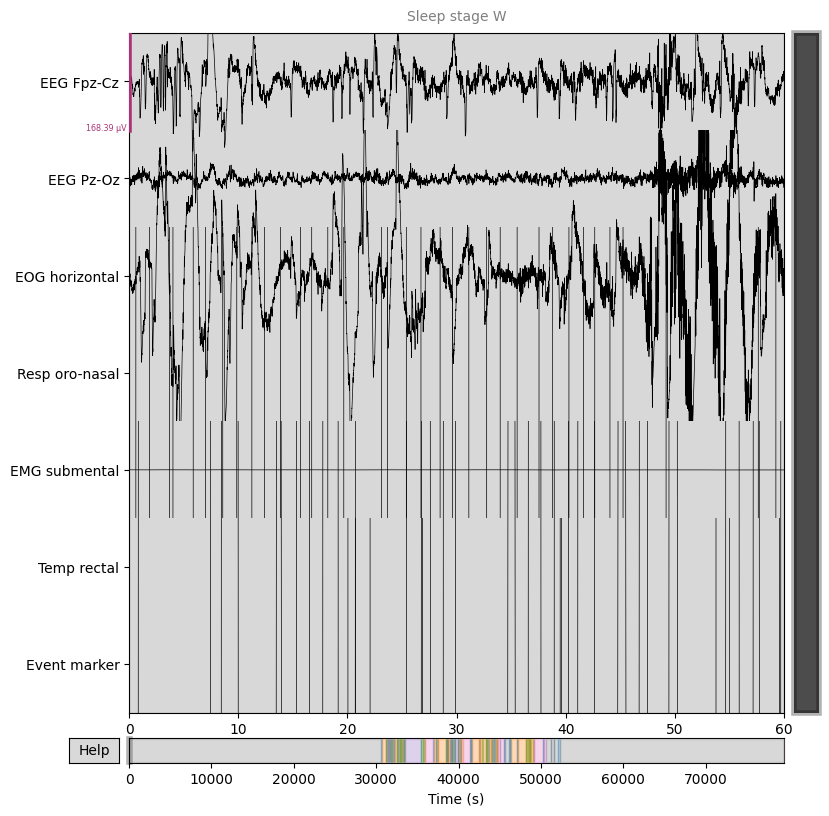

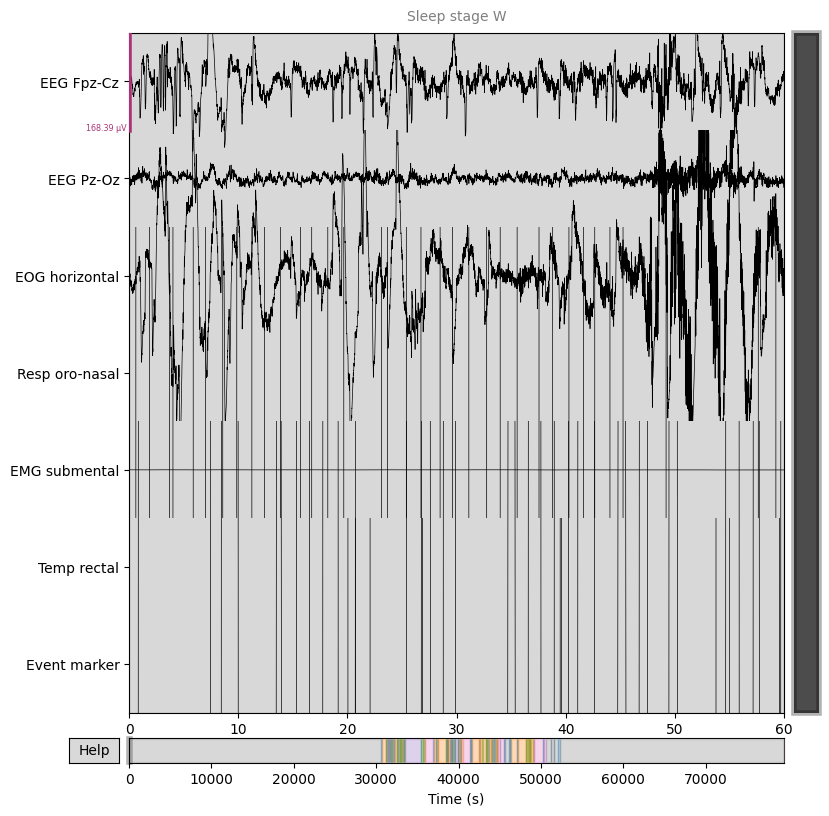

In [ ]:
print("\n===== PART 1: SINGLE SUBJECT =====")
data_dir = "/content/drive/MyDrive/archive/sleep-cassette"
psg_file = os.path.join(data_dir, "SC4001E0-PSG.edf")
hypnogram_file = os.path.join(data_dir, "SC4001EC-Hypnogram.edf")

raw = mne.io.read_raw_edf(psg_file, preload=True)
annotations = mne.read_annotations(hypnogram_file)
raw.set_annotations(annotations)

print("Channels:", raw.ch_names)
print("Sampling frequency:", raw.info['sfreq'])
raw.plot(duration=60, scalings='auto', title="Raw Signal Overview")

In [ ]:
# Pick EEG, EOG, EMG
channels = ['EEG Fpz-Cz', 'EOG horizontal', 'EMG submental']
raw.pick_channels(channels)
print("Selected channels:", raw.ch_names)

NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Selected channels: ['EEG Fpz-Cz', 'EOG horizontal', 'EMG submental']


In [ ]:
# Segment into epochs
sfreq = raw.info['sfreq']
epoch_len = int(sfreq * 30)
data = raw.get_data()
n_epochs = data.shape[1] // epoch_len
data = data[:, :n_epochs * epoch_len].reshape(3, n_epochs, epoch_len).transpose(1, 2, 0)
print("Data shape:", data.shape)

Data shape: (2650, 3000, 3)


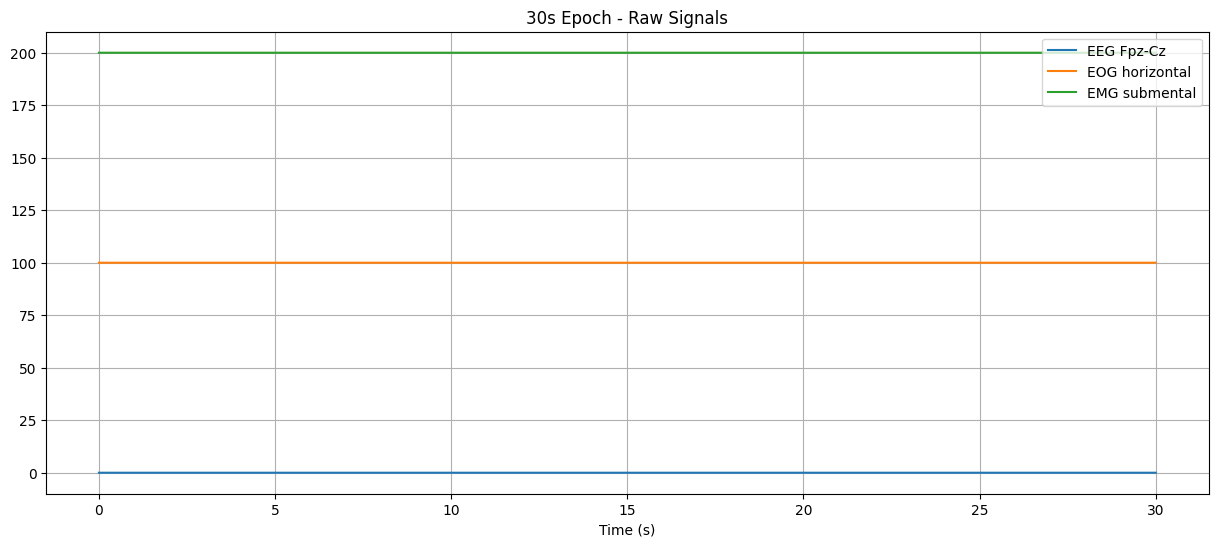

In [ ]:
# Plot 1st Epoch
plt.figure(figsize=(15, 6))
time = np.linspace(0, 30, epoch_len)
for i, ch in enumerate(channels):
    plt.plot(time, data[0, :, i] + i * 100, label=ch)
plt.title("30s Epoch - Raw Signals")
plt.xlabel("Time (s)")
plt.legend()
plt.grid(True)
plt.show()

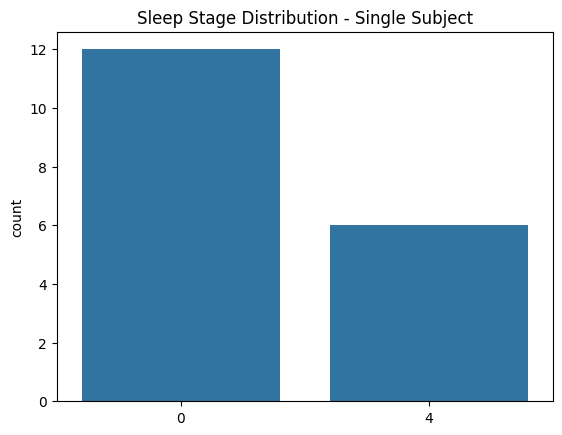

In [ ]:
# Extract labels
stage_map = {'W':0, 'N1':1, 'N2':2, 'N3':3, 'R':4}
labels = [stage_map[ann['description'].split()[-1]] for ann in annotations
          if 'Sleep stage' in ann['description'] and ann['description'].split()[-1] in stage_map]
labels = np.array(labels)

sns.countplot(x=labels)
plt.title("Sleep Stage Distribution - Single Subject")
plt.show()

In [ ]:
# Normalize & split
X = data.reshape(data.shape[0], -1)
X = StandardScaler().fit_transform(X).reshape(data.shape)
min_len = min(len(X), len(labels))
X, y = X[:min_len], labels[:min_len]
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (14, 3000, 3)
y_train shape: (14,)


In [ ]:
# Model for single subject
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.optimizers import Adam

model = Sequential([
    Conv1D(64, 7, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2])),
    MaxPooling1D(2), Dropout(0.3),
    Bidirectional(LSTM(64, return_sequences=True)),
    Dropout(0.3),
    Bidirectional(LSTM(32)),
    Dropout(0.3),
    Dense(32, activation='relu'), Dropout(0.2),
    Dense(5, activation='softmax')
])
model.compile(optimizer=Adam(0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 2994, 64)       │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 1497, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1497, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 1497, 128)      │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1497, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,917 (433.27 KB)

 Trainable params: 110,917 (433.27 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(X_train, y_train, epochs=30, batch_size=64, validation_data=(X_test, y_test))

Epoch 1/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step - accuracy: 0.1429 - loss: 1.6913 - val_accuracy: 0.2500 - val_loss: 1.5447
Epoch 2/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 420ms/step - accuracy: 0.3571 - loss: 1.5570 - val_accuracy: 0.5000 - val_loss: 1.4724
Epoch 3/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 591ms/step - accuracy: 0.2857 - loss: 1.5409 - val_accuracy: 0.7500 - val_loss: 1.3991
Epoch 4/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step - accuracy: 0.6429 - loss: 1.4007 - val_accuracy: 0.7500 - val_loss: 1.3127
Epoch 5/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step - accuracy: 0.6429 - loss: 1.3285 - val_accuracy: 0.7500 - val_loss: 1.2134
Epoch 6/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 247ms/step - accuracy: 0.6429 - loss: 1.2254 - val_accuracy: 0.7500 - val_loss: 1.1069
Epoch 7/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 253ms/step - accuracy: 0.8571 - loss: 1.1947 - val_accuracy: 0.7500 - val_loss: 0.9978
Epoch 8/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 326ms/step - accuracy: 0.5000 - loss: 1.1721 - val_accuracy: 0.7500 - val_loss: 

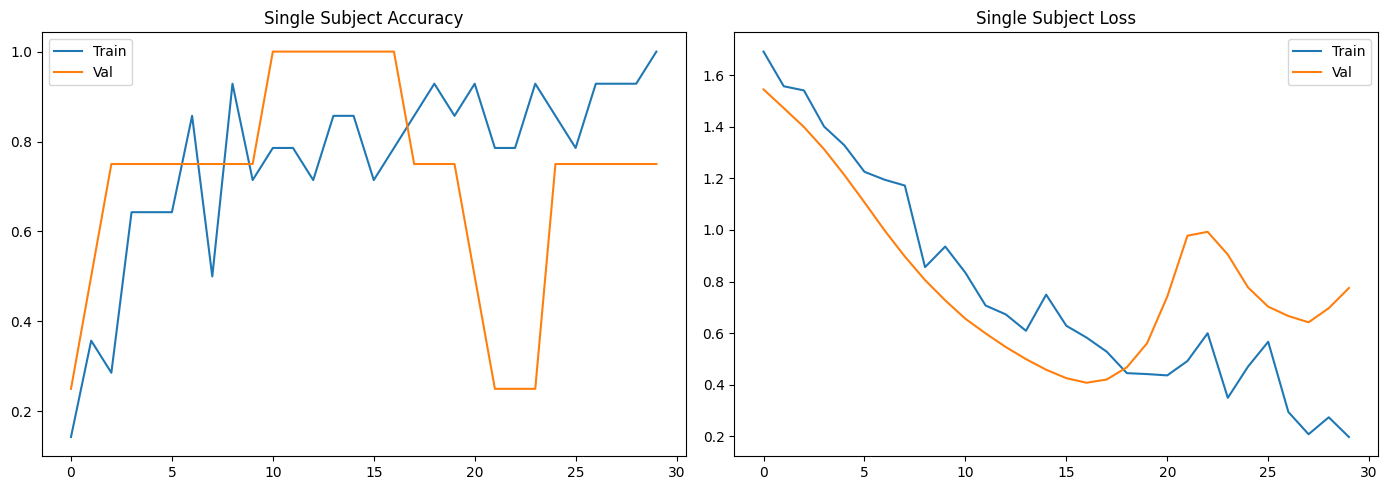

In [ ]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title("Single Subject Accuracy")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title("Single Subject Loss")
plt.legend()
plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 365ms/step
              precision    recall  f1-score   support

           0       1.00      0.67      0.80         3
           4       0.50      1.00      0.67         1

    accuracy                           0.75         4
   macro avg       0.75      0.83      0.73         4
weighted avg       0.88      0.75      0.77         4



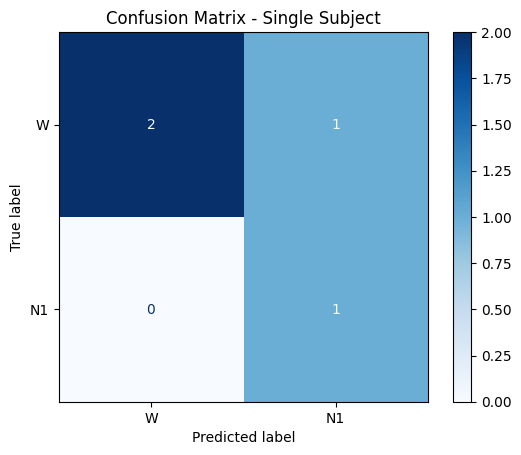

In [ ]:
# Evaluate
y_pred = model.predict(X_test)
y_pred_labels = np.argmax(y_pred, axis=1)
print(classification_report(y_test, y_pred_labels))
cm = confusion_matrix(y_test, y_pred_labels)
ConfusionMatrixDisplay(cm, display_labels=['W','N1','N2','N3','R'][:cm.shape[0]]).plot(cmap='Blues')
plt.title("Confusion Matrix - Single Subject")
plt.show()

# 2. Multi-Subject Full Pipeline

In [ ]:
print("===== PART 2: MULTI-SUBJECT TRAINING =====")

# Settings
data_dir = "/content/drive/MyDrive/archive/sleep-cassette"
stage_map = {'W': 0, 'N1': 1, 'N2': 2, 'N3': 3, 'R': 4}
preferred_channels = ['EEG Fpz-Cz', 'EOG horizontal', 'EMG submental']

# Load PSG and Hypnogram files
psg_files = sorted([f for f in os.listdir(data_dir) if f.endswith("PSG.edf")])
hypno_files = sorted([f for f in os.listdir(data_dir) if f.endswith("Hypnogram.edf")])

X_all, y_all = [], []

for psg, hyp in zip(psg_files, hypno_files):
    try:
        raw = mne.io.read_raw_edf(os.path.join(data_dir, psg), preload=True, verbose=False)
        ann = mne.read_annotations(os.path.join(data_dir, hyp))
        raw.set_annotations(ann)

        # Check channel availability
        available_channels = [ch for ch in preferred_channels if ch in raw.ch_names]
        if len(available_channels) < 1:
            print(f"Skipping {psg} - No EEG/EOG/EMG channels found.")
            continue

        raw.pick_channels(available_channels)
        print(f"✅ Using {psg} with channels: {available_channels}")

        # Segment into 30s epochs
        sfreq = raw.info['sfreq']
        ep_len = int(sfreq * 30)
        data = raw.get_data()
        n_ep = data.shape[1] // ep_len
        data = data[:, :n_ep * ep_len].reshape(len(available_channels), n_ep, ep_len).transpose(1, 2, 0)

        # Extract stage labels
        labels = [
            stage_map[a['description'].split()[-1]]
            for a in ann
            if 'Sleep stage' in a['description'] and a['description'].split()[-1] in stage_map
        ]

        # Align data and labels
        min_len = min(len(data), len(labels))
        if min_len < 1:
            print(f"Not enough epochs after alignment in {psg}. Skipping.")
            continue

        data = data[:min_len]
        labels = np.array(labels[:min_len])

        # Normalize and append
        data = StandardScaler().fit_transform(data.reshape(data.shape[0], -1)).reshape(data.shape)
        X_all.append(data)
        y_all.append(labels)

    except Exception as e:
        print(f"Error loading {psg}: {e}")

# Combine all data
if len(X_all) == 0:
    raise ValueError("No usable data loaded. Please check channel names or dataset path.")
X_all = np.vstack(X_all)
y_all = np.concatenate(y_all)

# Label distribution check
from collections import Counter
label_counts = Counter(y_all)
print(f"\nFinal dataset shape: {X_all.shape}")
print("Label distribution:", dict(label_counts))


===== PART 2: MULTI-SUBJECT TRAINING =====


<ipython-input-15-06412d9a1602>:16: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(os.path.join(data_dir, psg), preload=True, verbose=False)
<ipython-input-15-06412d9a1602>:16: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(os.path.join(data_dir, psg), preload=True, verbose=False)
<ipython-input-15-06412d9a1602>:16: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(os.path.join(data_dir, psg), preload=True, verbose=False)


NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


<ipython-input-15-06412d9a1602>:18: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(ann)


✅ Using SC4001E0-PSG.edf with channels: ['EEG Fpz-Cz', 'EOG horizontal', 'EMG submental']


<ipython-input-15-06412d9a1602>:16: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(os.path.join(data_dir, psg), preload=True, verbose=False)
<ipython-input-15-06412d9a1602>:16: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(os.path.join(data_dir, psg), preload=True, verbose=False)
<ipython-input-15-06412d9a1602>:16: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(os.path.join(data_dir, psg), preload=True, verbose=False)


... (591 outputs left out)

<ipython-input-15-06412d9a1602>:16: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(os.path.join(data_dir, psg), preload=True, verbose=False)
<ipython-input-15-06412d9a1602>:16: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(os.path.join(data_dir, psg), preload=True, verbose=False)
<ipython-input-15-06412d9a1602>:16: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(os.path.join(data_dir, psg), preload=True, verbose=False)


NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


<ipython-input-15-06412d9a1602>:18: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(ann)


✅ Using SC4822G0-PSG.edf with channels: ['EEG Fpz-Cz', 'EOG horizontal', 'EMG submental']

Final dataset shape: (5258, 3000, 3)
Label distribution: {np.int64(0): 3698, np.int64(4): 1560}


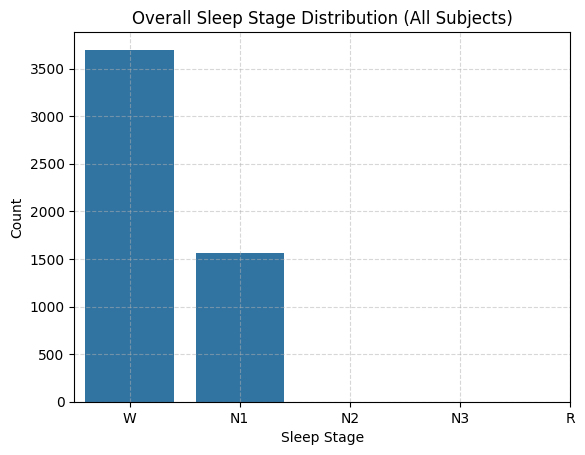

In [ ]:
# Plot label distribution
sns.countplot(x=y_all)
plt.xticks(ticks=[0,1,2,3,4], labels=['W', 'N1', 'N2', 'N3', 'R'])
plt.title("Overall Sleep Stage Distribution (All Subjects)")
plt.xlabel("Sleep Stage")
plt.ylabel("Count")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# Train-test split & class weights
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, stratify=y_all, test_size=0.2, random_state=42)
class_weights = dict(zip(np.unique(y_train), compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)))

In [ ]:
# Model (CNN + BiLSTM)
model = Sequential([
    Conv1D(64, 7, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2])),
    MaxPooling1D(2), Dropout(0.3),
    Bidirectional(LSTM(64, return_sequences=True)),
    Dropout(0.3),
    Bidirectional(LSTM(32)),
    Dropout(0.3),
    Dense(32, activation='relu'), Dropout(0.2),
    Dense(5, activation='softmax')
])
model.compile(optimizer=Adam(0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()



/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_1 (Conv1D)               │ (None, 2994, 64)       │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 1497, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1497, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 1497, 128)      │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1497, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,917 (433.27 KB)

 Trainable params: 110,917 (433.27 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Training
history = model.fit(X_train, y_train, epochs=30, batch_size=64, validation_data=(X_test, y_test), class_weight=class_weights)

Epoch 1/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 20s 232ms/step - accuracy: 0.4003 - loss: 1.1375 - val_accuracy: 0.7025 - val_loss: 0.6916
Epoch 2/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 18s 196ms/step - accuracy: 0.4837 - loss: 0.7958 - val_accuracy: 0.6892 - val_loss: 0.6898
Epoch 3/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 20s 196ms/step - accuracy: 0.5043 - loss: 0.7523 - val_accuracy: 0.2966 - val_loss: 0.7261
Epoch 4/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 20s 196ms/step - accuracy: 0.4912 - loss: 0.7307 - val_accuracy: 0.7034 - val_loss: 0.6586
Epoch 5/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 13s 196ms/step - accuracy: 0.5389 - loss: 0.7155 - val_accuracy: 0.7034 - val_loss: 0.6781
Epoch 6/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 21s 196ms/step - accuracy: 0.5128 - loss: 0.7138 - val_accuracy: 0.7034 - val_loss: 0.6767
Epoch 7/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 20s 195ms/step - accuracy: 0.5022 - loss: 0.7095 - val_accuracy: 0.7034 - val_loss: 0.6839
Epoch 8/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 21s 196ms/step - accuracy: 0.4711 - loss: 0.7020 - val_accu

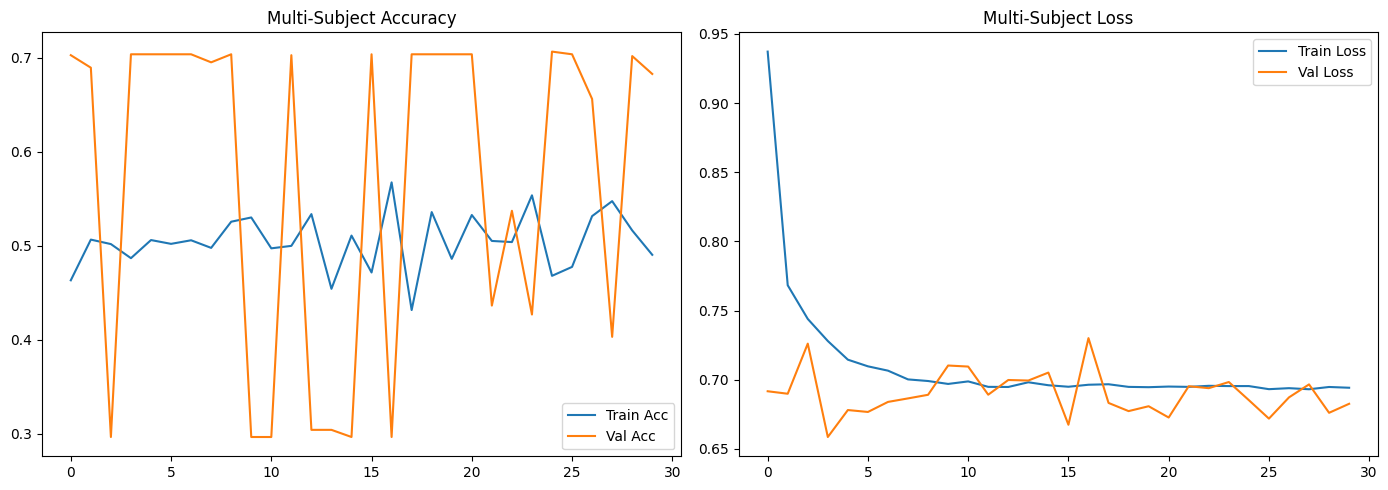

In [ ]:
# Evaluation plots
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title("Multi-Subject Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Multi-Subject Loss")
plt.legend()
plt.tight_layout()
plt.show()

33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step
Classification Report:
              precision    recall  f1-score   support

           W       0.70      0.94      0.81       740
          N1       0.00      0.00      0.00         0
          N2       0.00      0.00      0.00         0
          N3       0.00      0.00      0.00         0
           R       0.32      0.06      0.10       312

    accuracy                           0.68      1052
   macro avg       0.20      0.20      0.18      1052
weighted avg       0.59      0.68      0.60      1052



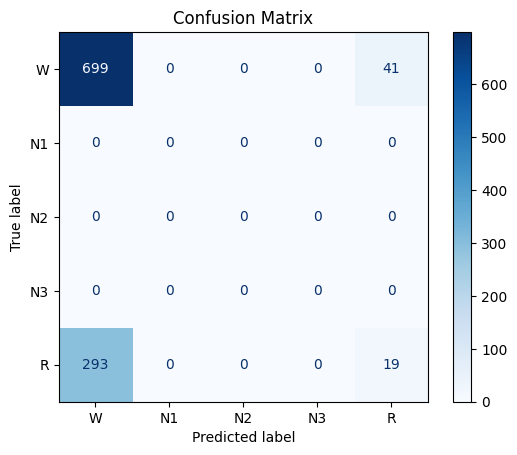

In [ ]:
# Predictions
y_pred = model.predict(X_test)
y_pred_labels = np.argmax(y_pred, axis=1)

# Classification report & confusion matrix
label_names = ['W', 'N1', 'N2', 'N3', 'R']
all_labels = [0, 1, 2, 3, 4]

print("Classification Report:")
print(classification_report(
    y_test, y_pred_labels,
    labels=all_labels,
    target_names=label_names,
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred_labels, labels=all_labels)
ConfusionMatrixDisplay(cm, display_labels=label_names).plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()


In [ ]:
# Baseline Model: CNN Only
cnn_model = Sequential([
    Conv1D(64, 7, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2])),
    MaxPooling1D(2), Dropout(0.3),
    Conv1D(128, 5, activation='relu'),
    MaxPooling1D(2), Dropout(0.3),
    GlobalAveragePooling1D(),
    Dense(64, activation='relu'), Dropout(0.2),
    Dense(5, activation='softmax')
])
cnn_model.compile(optimizer=Adam(0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn_history = cnn_model.fit(X_train, y_train, epochs=20, batch_size=64, validation_data=(X_test, y_test), class_weight=class_weights)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 12s 115ms/step - accuracy: 0.4053 - loss: 1.0611 - val_accuracy: 0.2966 - val_loss: 0.8093
Epoch 2/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.4856 - loss: 0.7363 - val_accuracy: 0.7034 - val_loss: 0.6630
Epoch 3/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.4954 - loss: 0.7219 - val_accuracy: 0.2966 - val_loss: 0.7122
Epoch 4/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.4816 - loss: 0.7077 - val_accuracy: 0.4886 - val_loss: 0.6953
Epoch 5/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.5225 - loss: 0.7024 - val_accuracy: 0.2966 - val_loss: 0.7082
Epoch 6/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.5037 - loss: 0.7020 - val_accuracy: 0.7034 - val_loss: 0.6687
Epoch 7/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.5235 - loss: 0.6915 - val_accuracy: 0.2966 - val_loss: 0.7178
Epoch 8/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.4312 - loss: 0.7081 - val_accuracy: 0.7034 -

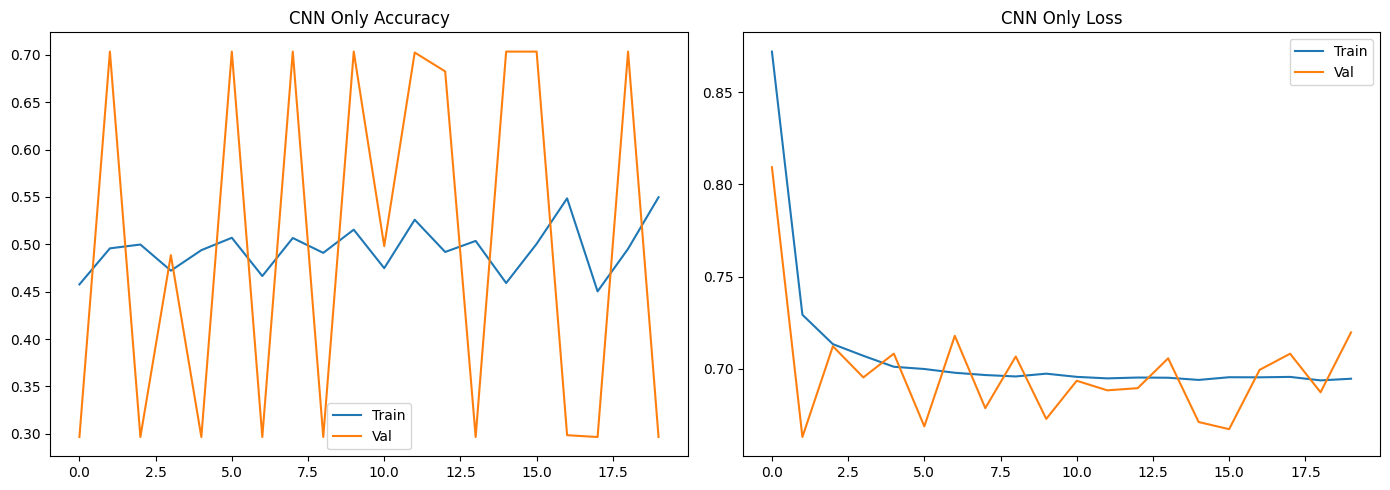

In [ ]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(cnn_history.history['accuracy'], label='Train')
plt.plot(cnn_history.history['val_accuracy'], label='Val')
plt.title("CNN Only Accuracy")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(cnn_history.history['loss'], label='Train')
plt.plot(cnn_history.history['val_loss'], label='Val')
plt.title("CNN Only Loss")
plt.legend()
plt.tight_layout()
plt.show()

33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
Classification Report - CNN Only:
              precision    recall  f1-score   support

           W       0.00      0.00      0.00       740
          N1       0.00      0.00      0.00         0
          N2       0.00      0.00      0.00         0
          N3       0.00      0.00      0.00         0
           R       0.30      1.00      0.46       312

    accuracy                           0.30      1052
   macro avg       0.06      0.20      0.09      1052
weighted avg       0.09      0.30      0.14      1052



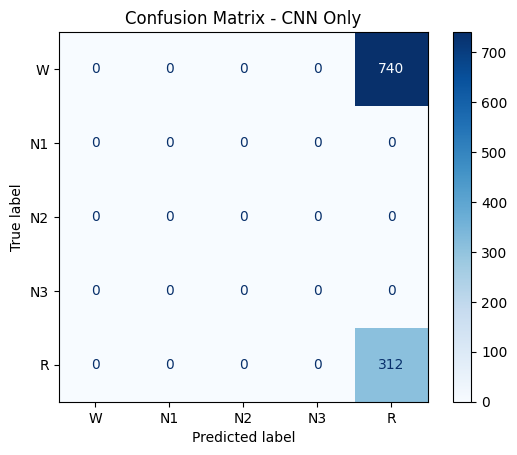

In [ ]:
# Predictions
cnn_y_pred = cnn_model.predict(X_test)
cnn_y_pred_labels = np.argmax(cnn_y_pred, axis=1)

# Define full label mapping
label_names = ['W', 'N1', 'N2', 'N3', 'R']
all_labels = [0, 1, 2, 3, 4]

# Print classification report with explicit labels
print("Classification Report - CNN Only:")
print(classification_report(
    y_test,
    cnn_y_pred_labels,
    labels=all_labels,
    target_names=label_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, cnn_y_pred_labels, labels=all_labels)
ConfusionMatrixDisplay(cm, display_labels=label_names).plot(cmap='Blues')
plt.title("Confusion Matrix - CNN Only")
plt.show()


In [ ]:
# ======================= SAVE FINAL MODEL ========================
model.save("/content/sleep_stage_model.h5")
print("Model saved as sleep_stage_model.h5")

Model saved as sleep_stage_model.h5


In [ ]:
# ======================= SUMMARY OF FINAL METRICS ========================
print("\n===== SUMMARY OF FINAL MODEL METRICS =====")
print("CNN+BiLSTM Accuracy:", accuracy_score(y_test, y_pred_labels))
print("CNN+BiLSTM F1 Score:", f1_score(y_test, y_pred_labels, average='weighted'))
print("CNN Only Accuracy:", accuracy_score(y_test, cnn_y_pred_labels))
print("CNN Only F1 Score:", f1_score(y_test, cnn_y_pred_labels, average='weighted'))



===== SUMMARY OF FINAL MODEL METRICS =====
CNN+BiLSTM Accuracy: 0.6825095057034221
CNN+BiLSTM F1 Score: 0.5980692863307943
CNN Only Accuracy: 0.2965779467680608
CNN Only F1 Score: 0.13567788767101902


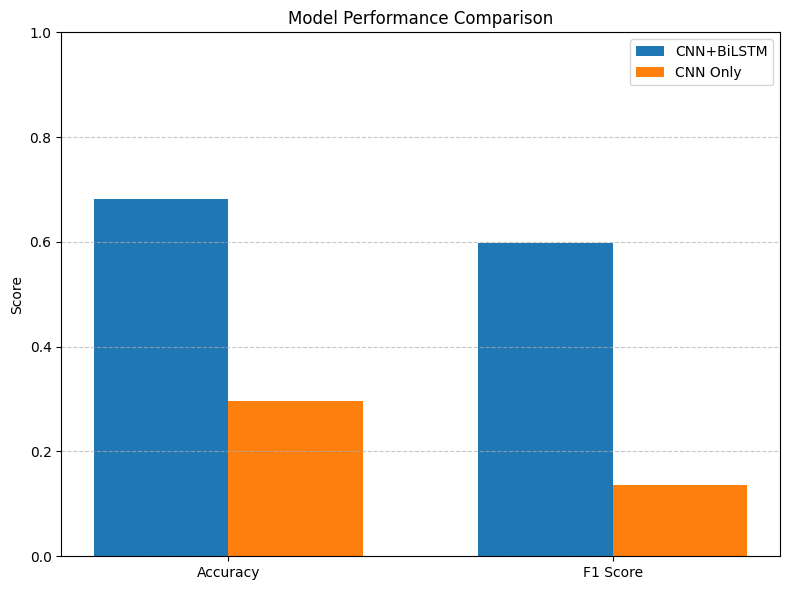

In [ ]:
# ======================= BAR CHART COMPARISON ========================
labels = ['Accuracy', 'F1 Score']
cnn_bilstm_scores = [
    accuracy_score(y_test, y_pred_labels),
    f1_score(y_test, y_pred_labels, average='weighted')
]
cnn_scores = [
    accuracy_score(y_test, cnn_y_pred_labels),
    f1_score(y_test, cnn_y_pred_labels, average='weighted')
]

x = np.arange(len(labels))  # [0, 1]
width = 0.35

plt.figure(figsize=(8, 6))
plt.bar(x - width/2, cnn_bilstm_scores, width, label='CNN+BiLSTM')
plt.bar(x + width/2, cnn_scores, width, label='CNN Only')
plt.xticks(x, labels)
plt.ylabel("Score")
plt.title("Model Performance Comparison")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
